<center><h1>xie_yiling_HW6</h1></center>

Name: yiling xie
<br>
Github Username: yilingx-333
<br>
USC ID: 3749312095

## 1. Tree-Based Methods

Import packages

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

### (a) Download the APS Failure data

In [4]:
train = pd.read_csv("../data/aps_failure_training_set.csv",
                    skiprows=20, na_values="na")
test = pd.read_csv("../data/aps_failure_test_set.csv",
                   skiprows=20, na_values="na")

print("Train:", train.shape)
print("Test:", test.shape)
train.head()

Train: (60000, 171)
Test: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common methods for handling missing values include deleting incomplete observations, mean or median imputation, KNN imputation, and model-based imputation. 

In this homework, I use median imputation because it is simple and less sensitive to extreme values. The training and test sets are imputed separately to avoid using information from one set to fill the other.

#### (ii) Calculate the coefficient of variation

In [5]:
y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})

X_train = train.drop(columns="class")
X_test = test.drop(columns="class")

X_train = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train),
    columns=X_train.columns
)
X_test = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_test),
    columns=X_test.columns
)

cv = X_train.std(ddof=1) / X_train.mean().replace(0, np.nan)
cv = cv.sort_values(ascending=False)

print("Missing values:", X_train.isna().sum().sum())
cv.head()

Missing values: 0


cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dtype: float64

#### (iii) Plot a correlation matrix

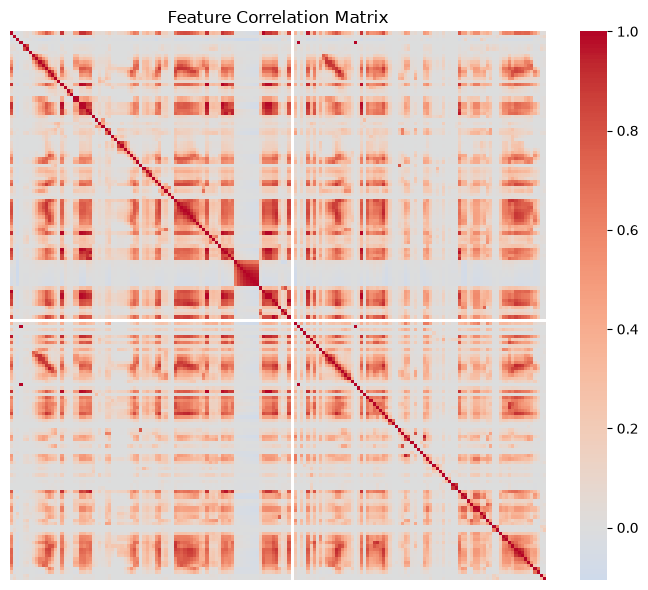

In [10]:
plt.figure(figsize=(7, 6))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0,
            xticklabels=False, yticklabels=False)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

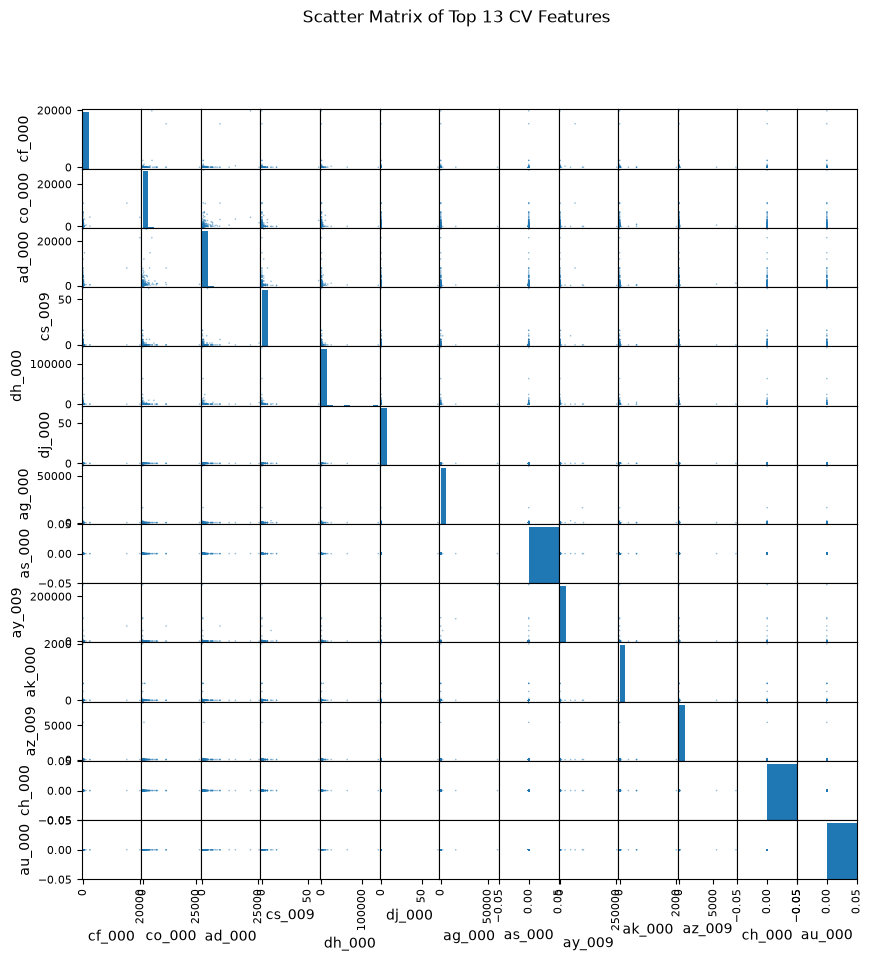

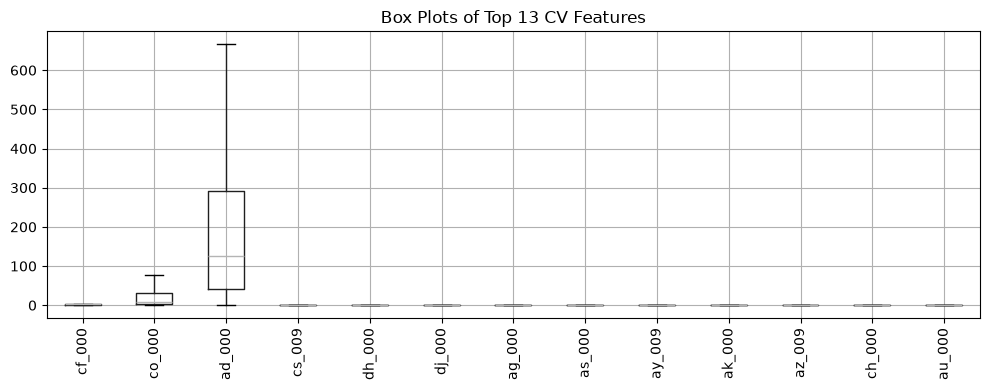

In [8]:
top = cv.head(13).index
sample = X_train[top].sample(1000, random_state=42)

pd.plotting.scatter_matrix(sample, figsize=(10, 10), s=5)
plt.suptitle("Scatter Matrix of Top 13 CV Features")
plt.show()

X_train[top].boxplot(figsize=(10, 4), rot=90, showfliers=False)
plt.title("Box Plots of Top 13 CV Features")
plt.tight_layout()
plt.show()

The plots show different distributions, scales, and some relationships among the selected features. However, the significance of these features cannot be determined from scatter plots alone. Statistical analysis and predictive models are needed.

#### (v) Is this data set imbalanced?

In [11]:
counts = y_train.value_counts().rename({0: "Negative", 1: "Positive"})
print(counts)
print("Positive rate:", f"{y_train.mean():.2%}")

class
Negative    59000
Positive     1000
Name: count, dtype: int64
Positive rate: 1.67%


The training set contains 59,000 negative and 1,000 positive observations. Only 1.67% of the observations are positive, so the dataset is seriously imbalanced.

### (c) Train a random forest

Training confusion matrix:
 [[59000     0]
 [    0  1000]]
Test confusion matrix:
 [[15609    16]
 [  104   271]]
Train AUC: 1.0000, Error: 0.0000
Test AUC:  0.9944, Error: 0.0075
OOB error: 0.0059


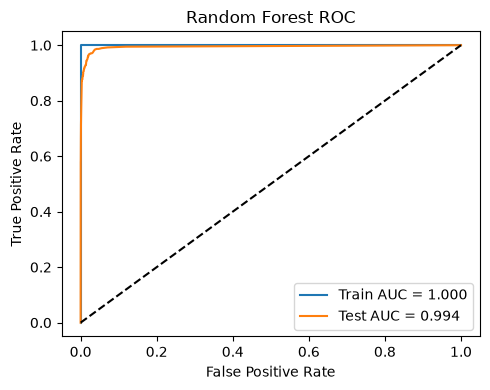

In [12]:
rf = RandomForestClassifier(
    n_estimators=200, oob_score=True,
    random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

def evaluate(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, prob)
    return confusion_matrix(y, pred), roc_auc_score(y, prob), 1 - accuracy_score(y, pred), fpr, tpr

tr = evaluate(rf, X_train, y_train)
te = evaluate(rf, X_test, y_test)

print("Training confusion matrix:\n", tr[0])
print("Test confusion matrix:\n", te[0])
print(f"Train AUC: {tr[1]:.4f}, Error: {tr[2]:.4f}")
print(f"Test AUC:  {te[1]:.4f}, Error: {te[2]:.4f}")
print(f"OOB error: {1 - rf.oob_score_:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(tr[3], tr[4], label=f"Train AUC = {tr[1]:.3f}")
plt.plot(te[3], te[4], label=f"Test AUC = {te[1]:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC")
plt.legend()
plt.tight_layout()
plt.show()

The random forest achieved a training AUC of 1.0000 and a test AUC of 0.9944. 

The training and test misclassification errors were 0.0000 and 0.0075. 

The OOB error was 0.0059, which is close to and slightly lower than the test error. 

Although overall performance was strong, the model missed 104 positive test observations, partly because of the serious class imbalance.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be addressed using class weights, balanced sampling, undersampling, or oversampling. 

Here, I use class weights so that mistakes on the minority positive class receive greater importance.

Training confusion matrix:
 [[58987    13]
 [    0  1000]]
Test confusion matrix:
 [[15571    54]
 [   95   280]]
Train AUC: 1.0000, Error: 0.0002
Test AUC:  0.9944, Error: 0.0093
OOB error: 0.0202


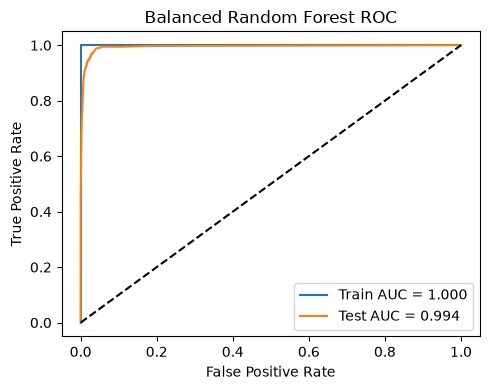

In [13]:
rf_bal = RandomForestClassifier(
    n_estimators=200, class_weight="balanced",
    oob_score=True, random_state=42, n_jobs=-1
)
rf_bal.fit(X_train, y_train)

trb = evaluate(rf_bal, X_train, y_train)
teb = evaluate(rf_bal, X_test, y_test)

print("Training confusion matrix:\n", trb[0])
print("Test confusion matrix:\n", teb[0])
print(f"Train AUC: {trb[1]:.4f}, Error: {trb[2]:.4f}")
print(f"Test AUC:  {teb[1]:.4f}, Error: {teb[2]:.4f}")
print(f"OOB error: {1 - rf_bal.oob_score_:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(trb[3], trb[4], label=f"Train AUC = {trb[1]:.3f}")
plt.plot(teb[3], teb[4], label=f"Test AUC = {teb[1]:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC")
plt.legend()
plt.tight_layout()
plt.show()

After class weighting, false negatives decreased from 104 to 95, while false positives increased from 16 to 54. 

The test AUC remained 0.9944, but the test error increased from 0.0075 to 0.0093. 

Therefore, balancing improved the detection of positive cases at the cost of more false alarms and a slightly higher overall error.

The balanced model had an OOB error of 0.0202, which was higher than the test error of 0.0093.

### (e) XGBoost and Model Trees

Best alpha: 0
CV error: 0.0063
Training confusion matrix:
 [[58966    34]
 [  173   827]]
Test confusion matrix:
 [[15604    21]
 [  110   265]]
Train AUC: 0.9978, Error: 0.0034
Test AUC:  0.9960, Error: 0.0082


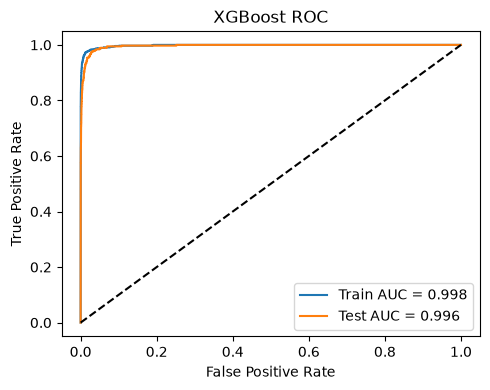

In [14]:
base_xgb = XGBClassifier(
    n_estimators=150, max_depth=3, learning_rate=0.1,
    objective="binary:logistic", eval_metric="logloss",
    tree_method="hist", random_state=42, n_jobs=1
)

cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
grid = GridSearchCV(
    base_xgb, {"reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=cv5, scoring="accuracy", n_jobs=-1
)
grid.fit(X_train, y_train)

xgb = grid.best_estimator_
trx = evaluate(xgb, X_train, y_train)
tex = evaluate(xgb, X_test, y_test)

print("Best alpha:", grid.best_params_["reg_alpha"])
print(f"CV error: {1 - grid.best_score_:.4f}")
print("Training confusion matrix:\n", trx[0])
print("Test confusion matrix:\n", tex[0])
print(f"Train AUC: {trx[1]:.4f}, Error: {trx[2]:.4f}")
print(f"Test AUC:  {tex[1]:.4f}, Error: {tex[2]:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(trx[3], trx[4], label=f"Train AUC = {trx[1]:.3f}")
plt.plot(tex[3], tex[4], label=f"Test AUC = {tex[1]:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC")
plt.legend()
plt.tight_layout()
plt.show()

Five-fold cross-validation selected alpha = 0, indicating that additional L1 regularization did not improve validation accuracy among the tested values. The CV error was 0.0063, compared with a test error of 0.0082. The training and test AUC values were 0.9978 and 0.9960, showing strong classification performance, although 110 positive test observations were misclassified.

### (f) Use SMOTE to pre-process your data

Best alpha: 1
CV error: 0.0161
Training confusion matrix:
 [[58179   821]
 [   66   934]]
Test confusion matrix:
 [[15372   253]
 [   32   343]]
Train AUC: 0.9961, Error: 0.0148
Test AUC:  0.9936, Error: 0.0178


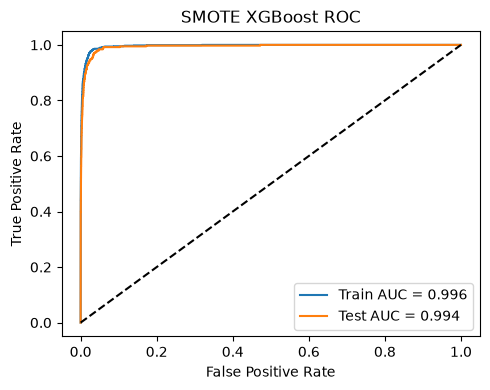

In [15]:
from imblearn.pipeline import Pipeline as ImbPipeline

smote_xgb = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        n_estimators=150, max_depth=3, learning_rate=0.1,
        objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", random_state=42, n_jobs=-1
    ))
])

grid_smote = GridSearchCV(
    smote_xgb,
    {"model__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=cv5, scoring="accuracy", n_jobs=1
)
grid_smote.fit(X_train, y_train)

xgb_smote = grid_smote.best_estimator_
trs = evaluate(xgb_smote, X_train, y_train)
tes = evaluate(xgb_smote, X_test, y_test)

print("Best alpha:", grid_smote.best_params_["model__reg_alpha"])
print(f"CV error: {1 - grid_smote.best_score_:.4f}")
print("Training confusion matrix:\n", trs[0])
print("Test confusion matrix:\n", tes[0])
print(f"Train AUC: {trs[1]:.4f}, Error: {trs[2]:.4f}")
print(f"Test AUC:  {tes[1]:.4f}, Error: {tes[2]:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(trs[3], trs[4], label=f"Train AUC = {trs[1]:.3f}")
plt.plot(tes[3], tes[4], label=f"Test AUC = {tes[1]:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SMOTE XGBoost ROC")
plt.legend()
plt.tight_layout()
plt.show()

SMOTE reduced the number of false negatives from 110 to 32 and increased true positives from 265 to 343. However, false positives increased from 21 to 253, and the test error increased from 0.0082 to 0.0178. The test AUC decreased slightly from 0.9960 to 0.9936. Therefore, SMOTE substantially improved minority-class detection, but produced more false alarms and a higher overall error.

## 2. ISLR 6.6.3

As s increases from 0, the lasso constraint becomes less restrictive and the model becomes more flexible.

(a) Training RSS: (iv) steadily decreases.

(b) Test RSS: (ii) decreases initially and then eventually increases because of overfitting.

(c) Variance: (iii) steadily increases.

(d) Squared bias: (iv) steadily decreases.

(e) Irreducible error: (v) remains constant because it does not depend on the model.

## 3. ISLR 6.6.5

Let x1 = x11 = x12 and x2 = x21 = x22.

(a) The ridge regression problem is to minimize:

(y1 - x1*b1 - x1*b2)^2 + (y2 - x2*b1 - x2*b2)^2 + lambda*(b1^2 + b2^2)

(b) The RSS depends only on b1 + b2. For a fixed sum, the ridge penalty is smallest when the coefficients are equal. Therefore, b1 = b2.

(c) The lasso problem is to minimize:

(y1 - x1*b1 - x1*b2)^2 + (y2 - x2*b1 - x2*b2)^2 + lambda*(|b1| + |b2|)

(d) Let c = b1 + b2 be the optimal total coefficient. Any two coefficients with the same sign and sum c have the same RSS and lasso penalty. If c is positive, any b1 between 0 and c, together with b2 = c - b1, is optimal. Therefore, the lasso solution is not unique.

## 4. ISLR 8.4.5

Six trees give a probability greater than 0.5, so six trees predict Red and four predict Green. Therefore, majority vote classifies the observation as Red.

The average probability is:

(0.10 + 0.15 + 0.20 + 0.20 + 0.55 + 0.60 + 0.60 + 0.65 + 0.70 + 0.75) / 10 = 0.45

Since 0.45 is less than 0.50, the average-probability method classifies the observation as Green.

## 5. ISLR 9.7.3

(a) Red observations: (3,4), (2,2), (4,4), and (1,4). Blue observations: (2,1), (4,3), and (4,1).

(b) The optimal separating hyperplane is:

0.5 - X1 + X2 = 0

Equivalently, X2 = X1 - 0.5.

(c) Classify an observation as Red if 0.5 - X1 + X2 > 0, and Blue otherwise. Therefore, b0 = 0.5, b1 = -1, and b2 = 1.

(d) The margin boundaries are X2 = X1 and X2 = X1 - 1. The distance from the separating hyperplane to either boundary is 1/(2*sqrt(2)).

(e) The support vectors are observations 2, 3, 5, and 6: (2,2), (4,4), (2,1), and (4,3).

(f) Observation 7, (4,1), is not a support vector and is far from the margin. A small movement of this point will not affect the maximal margin hyperplane.

(g) One non-optimal separating hyperplane is:

0.2 - X1 + X2 = 0

(h) Adding a Blue observation at (3,3) makes the two classes no longer linearly separable.

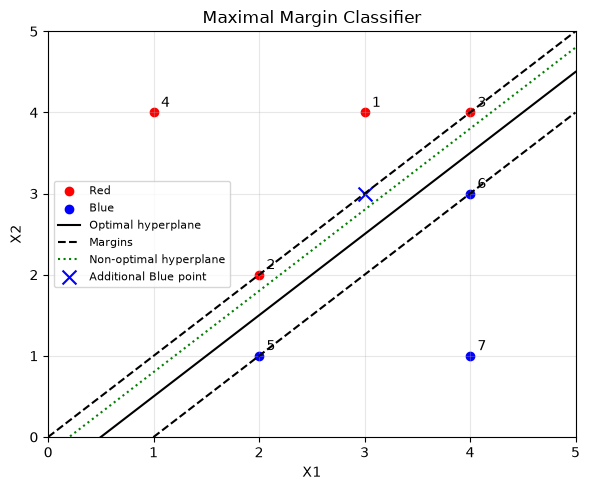

In [16]:
red = np.array([[3,4], [2,2], [4,4], [1,4]])
blue = np.array([[2,1], [4,3], [4,1]])
x = np.linspace(0, 5, 100)

plt.figure(figsize=(6, 5))
plt.scatter(red[:,0], red[:,1], c="red", label="Red")
plt.scatter(blue[:,0], blue[:,1], c="blue", label="Blue")

plt.plot(x, x - 0.5, "k-", label="Optimal hyperplane")
plt.plot(x, x, "k--", label="Margins")
plt.plot(x, x - 1, "k--")
plt.plot(x, x - 0.2, "g:", label="Non-optimal hyperplane")

plt.scatter(3, 3, c="blue", marker="x", s=100,
            label="Additional Blue point")

for i, (a, b) in enumerate(np.vstack((red, blue)), 1):
    plt.text(a + 0.07, b + 0.07, str(i))

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Maximal Margin Classifier")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()